<a href="https://colab.research.google.com/github/jayavenkatasai224/ITA0514-Computer-Vision/blob/main/ex_no_33.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving flower.2.webp to flower.2 (5).webp
Original Grayscale Image


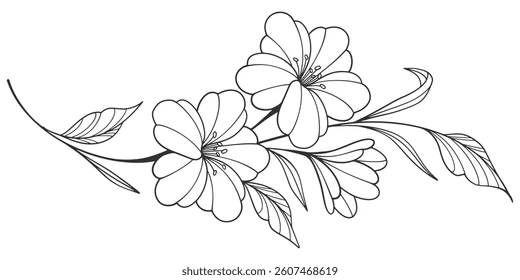

Low-Pass Filtered Image


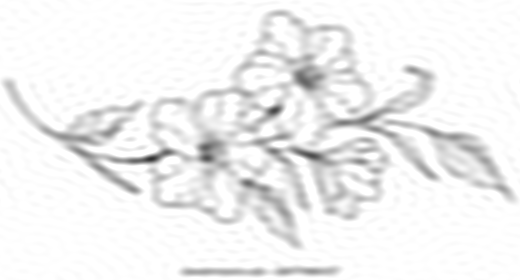

In [7]:

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload flower image
uploaded = files.upload()

# Read image
filename = next(iter(uploaded))
img = cv2.imread(filename)

if img is None:
    print("Image not found")
else:
    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Fourier Transform
    dft = np.fft.fft2(gray)

    # Shift zero frequency to center
    dft_shift = np.fft.fftshift(dft)

    # Get image dimensions
    rows, cols = gray.shape
    crow, ccol = rows // 2, cols // 2

    # Create low-pass filter mask
    mask = np.zeros((rows, cols), np.uint8)

    # Set circular region
    cv2.circle(mask, (ccol, crow), 30, 1, -1)

    # Apply mask
    filtered = dft_shift * mask

    # Inverse Fourier Transform
    inverse_shift = np.fft.ifftshift(filtered)
    img_back = np.fft.ifft2(inverse_shift)

    # Convert output to uint8
    result = np.abs(img_back)
    result = np.uint8(np.clip(result, 0, 255))

    # Display images
    print("Original Grayscale Image")
    cv2_imshow(gray)

    print("Low-Pass Filtered Image")
    cv2_imshow(result)
